# PCE excess inflation contributions

Decomposes PCE inflation into excess contributions relative to a benchmark period, using the 199 detailed components in `Detailed PCE.xlsx`. Headline and core are run separately with the same method.

1. **Component inflation**: annualized log price change over `LOOKBACK_MONTHS`.
2. **Component benchmark**: the average of that annualized log change over the benchmark years. With a 12-month lookback this is the average log y/y change, so it does not depend on the lookback horizon.
3. **Weights**: Törnqvist weights, the average of each component's spending share at the start and end of the window. For core, shares are taken within core.
4. **Anchor**: component benchmarks weighted by average spending shares during the benchmark period. This is the aggregate inflation rate the benchmark period delivered (for example, about 2% core over 2000–2008).
5. **Decomposition**: inflation − anchor = component excess + mix shift
   - Component excess for component *i*: w<sub>i,now</sub> × (π<sub>i</sub> − b<sub>i</sub>), how far each component runs above its own benchmark pace.
   - Mix shift for component *i*: (w<sub>i,now</sub> − w̄<sub>i</sub>) × (b<sub>i</sub> − anchor). It is nonzero only when spending has moved toward components whose normal inflation is above (or below) the anchor.

Both pieces are computed in log points and converted to percentage points with one common factor per month, so they add exactly to reconstructed inflation minus the anchor. The small residual against BEA's official series is reported but not distributed.

Every result is stored in a named DataFrame (listed at the top of each section). Charts are in separate cells and only read those DataFrames.

In [1]:
# User inputs
API_KEY = "FD4E7F46-5D89-4CA8-BE48-4F5997F83B3B"
LOOKBACK_MONTHS = 12  # for example: 12, 6, or 3
START_YEAR = 2000
BENCHMARK = "2000-2019"  # inclusive start and end years

CATEGORIES_FILE = "Detailed PCE.xlsx"

In [2]:
import json
from urllib.parse import urlencode
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

bench_start, bench_end = (int(year) for year in BENCHMARK.split("-"))
benchmark_dates = pd.period_range(f"{bench_start}-01", f"{bench_end}-12", freq="M")

categories = pd.read_excel(CATEGORIES_FILE).dropna(subset=["Line Item"])
categories["Line Item"] = categories["Line Item"].astype(int)
categories = categories.set_index("Line Item")
assert len(categories) == 199 and categories.index.is_unique
group_order = categories["Major Group"].unique().tolist()
descriptions = categories["Description"].str.strip()


def get_bea_table(dataset, table, years):
    params = {
        "UserID": API_KEY,
        "method": "GetData",
        "DataSetName": dataset,
        "TableName": table,
        "Frequency": "M",
        "Year": ",".join(map(str, years)),
        "ResultFormat": "JSON",
    }
    with urlopen("https://apps.bea.gov/api/data/?" + urlencode(params), timeout=60) as response:
        results = json.load(response)["BEAAPI"]["Results"]
    if "Data" not in results:
        raise RuntimeError(f"BEA API error: {results}")
    data = pd.DataFrame(results["Data"])
    data["Date"] = pd.PeriodIndex(data["TimePeriod"].str.replace("M", "-"), freq="M")
    data["Value"] = pd.to_numeric(data["DataValue"].str.replace(",", ""), errors="coerce")
    data["LineNumber"] = data["LineNumber"].astype(int)
    return data


def to_panel(data):
    return data.pivot(index="Date", columns="LineNumber", values="Value").reindex(columns=categories.index)


first_year = min(START_YEAR, bench_start) - int(np.ceil(max(LOOKBACK_MONTHS, 12) / 12))
years = range(first_year, pd.Timestamp.today().year + 1)
prices = get_bea_table("NIUnderlyingDetail", "U20404", years)
spending = get_bea_table("NIUnderlyingDetail", "U20405", years)
official = get_bea_table("NIPA", "T20804", years)

# BEA renumbers lines in comprehensive updates, so confirm each line still carries the expected series
price_codes = prices.drop_duplicates("LineNumber").set_index("LineNumber")["SeriesCode"]
assert price_codes.reindex(categories.index).eq(categories["Code"]).all(), \
    "BEA line numbers no longer match the Code column in the Excel file."

price_panel = to_panel(prices)
spending_panel = to_panel(spending).reindex(price_panel.index)
official_index = official.pivot_table(index="Date", columns="SeriesCode", values="Value", aggfunc="first")
print(f"Data through {price_panel.index.max()}; benchmark {BENCHMARK}; {LOOKBACK_MONTHS}-month lookback.")

Data through 2026-09; benchmark 2000-2019; 12-month lookback.


## Decomposition

`decompose(items, official_series, lookback=None)` returns four DataFrames for a set of components. It uses `LOOKBACK_MONTHS` unless a different `lookback` is passed (the persistence section uses 3 and 12).

| DataFrame | Rows | Contents |
|---|---|---|
| `summary` | months | reconstructed and official inflation, anchor, excess over anchor, component excess, mix shift |
| `groups` | months | contribution of each Major Group, plus `Mix shift` and `Total` (= excess over anchor) |
| `components` | components | latest month: current and benchmark inflation, weights, excess contribution and mix shift, largest contributors first |
| `contributions` | months | excess contribution of every component (columns are BEA line items) |

In [5]:
def decompose(items, official_series, lookback=None):
    L = lookback or LOOKBACK_MONTHS
    annualize = 12 / L
    prices = price_panel[items]
    shares = spending_panel[items].div(spending_panel[items].sum(axis=1), axis=0)
    weights = (shares + shares.shift(L)) / 2                       # Törnqvist weights
    log_change = annualize * np.log(prices / prices.shift(L))      # annualized log price change

    benchmark_sample = log_change.reindex(benchmark_dates)
    assert benchmark_sample.notna().all().all(), "Missing component data in the benchmark period."
    benchmark = benchmark_sample.mean()                            # component benchmarks
    period_weights = shares.reindex(benchmark_dates).mean()        # average benchmark-period shares
    anchor = (period_weights * benchmark).sum()                    # aggregate benchmark

    keep = (
        weights.notna().all(axis=1)
        & log_change.notna().all(axis=1)
        & (weights.index >= pd.Period(f"{START_YEAR}-01", freq="M"))
    )
    weights, log_change = weights[keep], log_change[keep]
    assert np.allclose(weights.sum(axis=1), 1)

    inflation_log = (weights * log_change).sum(axis=1)
    excess_log = weights * (log_change - benchmark)
    mix_log = (weights - period_weights) * (benchmark - anchor)

    # One common factor per month converts log points to percentage points so the pieces add up exactly
    gap_log = inflation_log - anchor
    to_pp = (100 * (np.exp(inflation_log) - np.exp(anchor)) / gap_log).where(
        gap_log.abs() > 1e-12, 100 * np.exp(anchor)
    )
    contributions = excess_log.mul(to_pp, axis=0)
    mix_shift = mix_log.mul(to_pp, axis=0)

    inflation = 100 * np.expm1(inflation_log)
    anchor_rate = 100 * np.expm1(anchor)
    official_rate = 100 * ((official_series / official_series.shift(L)) ** annualize - 1)
    summary = pd.DataFrame({
        "Reconstructed inflation": inflation,
        "Official BEA inflation": official_rate.reindex(inflation.index),
        "Benchmark anchor": anchor_rate,
        "Excess over anchor": inflation - anchor_rate,
        "Component excess": contributions.sum(axis=1),
        "Mix shift": mix_shift.sum(axis=1),
    })

    groups = contributions.T.groupby(categories.loc[items, "Major Group"]).sum().T
    groups = groups[[group for group in group_order if group in groups.columns]]
    groups["Mix shift"] = summary["Mix shift"]
    groups["Total"] = summary["Excess over anchor"]

    latest = summary.index[-1]
    components = categories.loc[items, ["Description", "Major Group"]].assign(**{
        "Current inflation (%)": 100 * np.expm1(log_change.loc[latest]),
        "Benchmark (%)": 100 * np.expm1(benchmark),
        "Current weight (%)": 100 * weights.loc[latest],
        "Benchmark-period weight (%)": 100 * period_weights,
        "Excess contribution (pp)": contributions.loc[latest],
        "Mix shift (pp)": mix_shift.loc[latest],
    }).sort_values("Excess contribution (pp)", ascending=False)

    for frame in (summary, groups, contributions):
        frame.index.name = "Date"
    return summary, groups, components, contributions

In [6]:
POSITIVE, NEGATIVE, OFFICIAL, MUTED = "#e34948", "#2a78d6", "#eb6834", "#898781"


def plot_results(summary, groups, name):
    dates = summary.index.to_timestamp()

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(dates, summary["Reconstructed inflation"], color=NEGATIVE, lw=2, label="Reconstructed")
    ax.plot(dates, summary["Official BEA inflation"], color=OFFICIAL, lw=2, label="Official BEA")
    ax.axhline(summary["Benchmark anchor"].iloc[0], color=MUTED, lw=1, ls="--", label=f"{BENCHMARK} anchor")
    ax.set_title(f"{name} inflation ({LOOKBACK_MONTHS}-month, annualized)")
    ax.set_ylabel("Percent")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(dates, summary["Excess over anchor"], color=POSITIVE, lw=2)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"{name} inflation minus the {BENCHMARK} anchor")
    ax.set_ylabel("Percentage points")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

    latest = groups.iloc[-1].drop("Total")
    bars = pd.concat([latest.drop("Mix shift").sort_values(), latest[["Mix shift"]]])
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(bars.index, bars, color=np.where(bars >= 0, POSITIVE, NEGATIVE),
            hatch=["//" if label == "Mix shift" else "" for label in bars.index], edgecolor="white")
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{name} excess contributions by Major Group, {groups.index[-1]}")
    ax.set_xlabel("Percentage points")
    plt.tight_layout()
    plt.show()

## 1. Headline PCE

All 199 components, compared with BEA's official PCE price index (`DPCERG`).

DataFrames: `headline_summary`, `headline_groups`, `headline_components`, `headline_contributions`.

In [5]:
headline_summary, headline_groups, headline_components, headline_contributions = decompose(
    categories.index.tolist(), official_index["DPCERG"]
)
headline_summary.tail(12).round(3)

,Reconstructed inflation,Official BEA inflation,Benchmark anchor,Excess over anchor,Component excess,Mix shift
Date,,,,,,
2025-10,2.671,2.657,1.867,0.804,0.805,-0.001
2025-11,2.693,2.710,1.867,0.827,0.830,-0.004
2025-12,2.773,2.777,1.867,0.907,0.911,-0.004
2026-01,2.726,2.728,1.867,0.859,0.856,0.003
2026-02,2.794,2.801,1.867,0.927,0.931,-0.004
2026-03,3.380,3.365,1.867,1.514,1.519,-0.005
2026-04,3.665,3.574,1.867,1.799,1.801,-0.003
2026-05,3.897,3.823,1.867,2.030,2.033,-0.002
2026-06,3.505,3.453,1.867,1.638,1.644,-0.005


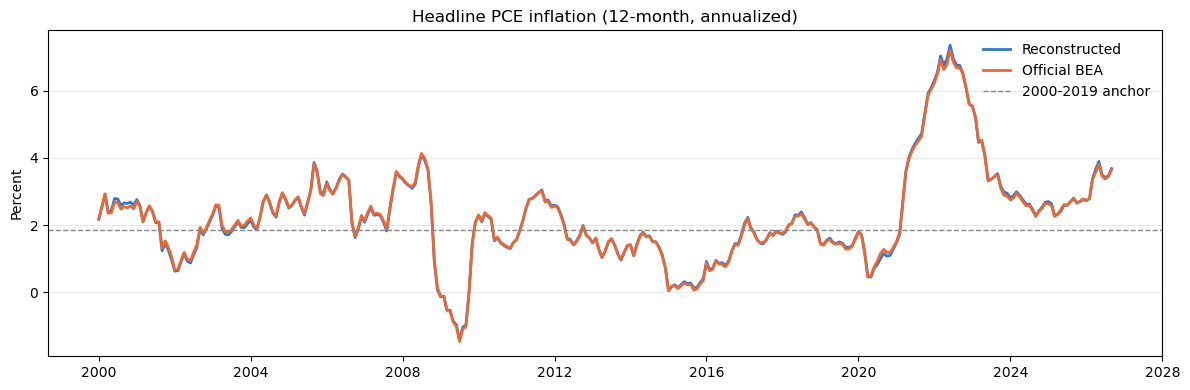

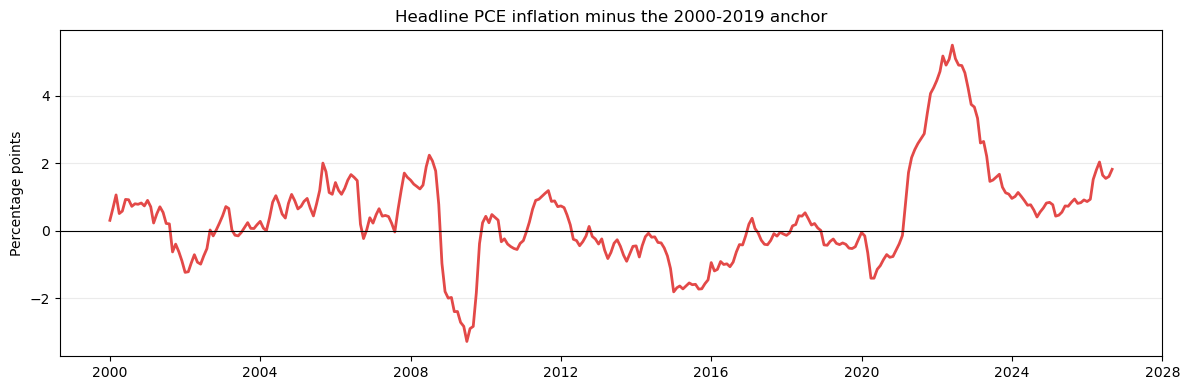

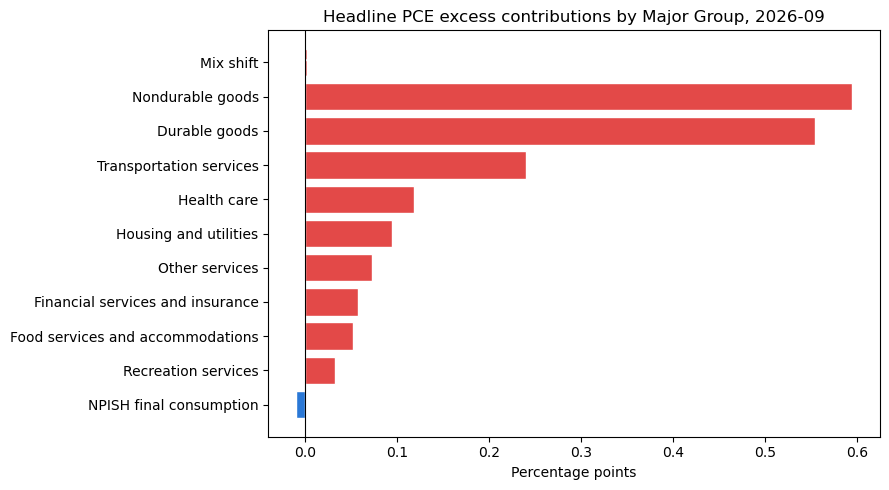

In [6]:
plot_results(headline_summary, headline_groups, "Headline PCE")

## 2. Core PCE

The 171 components classified as Core in `Detailed PCE.xlsx`, with weights taken within core. The control is BEA's official core PCE price index (`DPCCRG`).

DataFrames: `core_summary`, `core_groups`, `core_components`, `core_contributions`.

In [7]:
core_items = categories.index[categories["Classification"].eq("Core")].tolist()
core_summary, core_groups, core_components, core_contributions = decompose(core_items, official_index["DPCCRG"])
core_summary.tail(12).round(3)

,Reconstructed inflation,Official BEA inflation,Benchmark anchor,Excess over anchor,Component excess,Mix shift
Date,,,,,,
2025-10,2.722,2.705,1.765,0.957,0.923,0.034
2025-11,2.703,2.721,1.765,0.938,0.907,0.031
2025-12,2.865,2.872,1.765,1.101,1.072,0.029
2026-01,2.931,2.938,1.765,1.167,1.130,0.036
2026-02,2.948,2.959,1.765,1.183,1.154,0.029
2026-03,3.116,3.105,1.765,1.352,1.327,0.025
2026-04,3.167,3.084,1.765,1.403,1.377,0.026
2026-05,3.243,3.162,1.765,1.479,1.451,0.027
2026-06,3.101,3.041,1.765,1.336,1.309,0.027


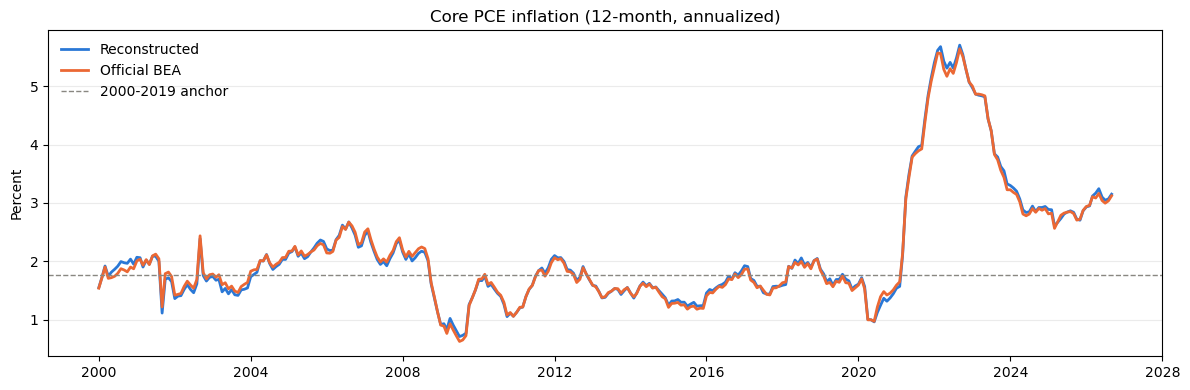

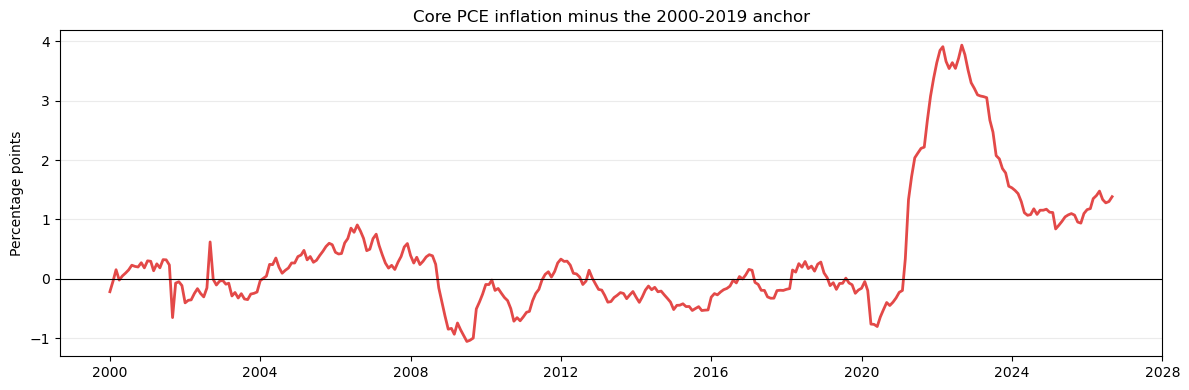

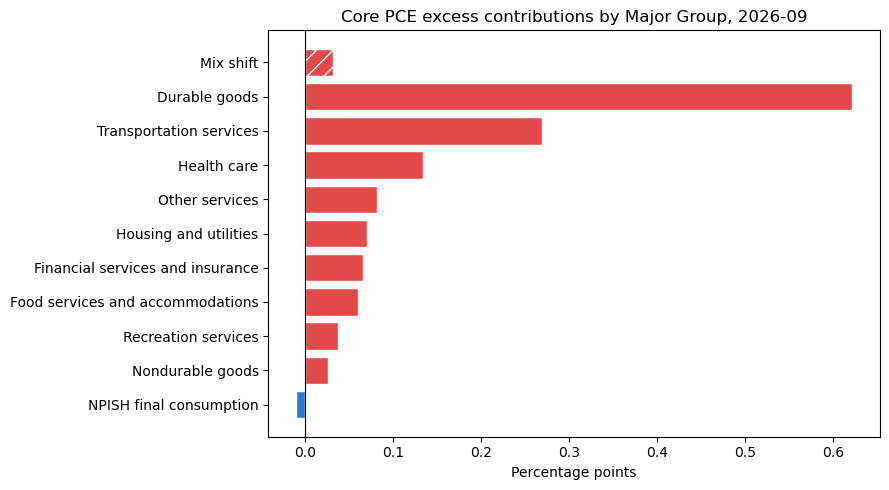

In [8]:
plot_results(core_summary, core_groups, "Core PCE")

In [15]:
core_contributions.sum(axis=1).tail(2)

Date
2026-08    1.275839
2026-09    1.352908
Freq: M, dtype: float64

In [14]:
core_components

,Description,Major Group,Current inflation (%),Benchmark (%),Current weight (%),Benchmark-period weight (%),Excess contribution (pp),Mix shift (pp)
Line Item,,,,,,,,
50,Computer software and accessories,Durable goods,18.483063,-5.331569,1.232394,0.537428,0.283327,-0.051469
207,Air transportation (64),Transportation services,20.510859,1.336370,1.116786,0.820093,0.198285,-0.001283
49,Personal computers/tablets and peripheral equi...,Durable goods,9.698936,-12.704911,0.566818,0.472106,0.132667,-0.014883
127,"Games, toys, and hobbies",Nondurable goods,6.637810,-6.235924,0.764374,0.613775,0.100756,-0.012634
162,Owner-occupied stationary homes,Housing and utilities,3.260939,2.652176,12.980506,12.834613,0.078636,0.001298
...,...,...,...,...,...,...,...,...
156,Tenant-occupied stationary homes and landlord ...,Housing and utilities,2.782192,3.149523,4.026752,3.830871,-0.014718,0.002712
279,Net motor vehicle and other transportation ins...,Financial services and insurance,0.304718,2.916508,0.584407,0.684967,-0.015391,-0.001159
133,Household paper products,Nondurable goods,-2.215671,2.580023,0.335067,0.383422,-0.016437,-0.000395


## 3. Persistence and concentration of core excess

Is excess inflation coming from the same components period after period (persistent), or do the leaders change each time (rotating)? Consecutive 12-month windows share 11 of their 12 months, so they look persistent by construction. This section therefore uses windows that don't overlap: 3-month annualized contributions at each quarter end, and the latest 12 months against the 12 months before.

- **Correlation with prior quarter**: the correlation, across components, between this quarter's contributions and last quarter's. Near zero means rotation; higher means the same components keep running hot.
- **Top-10 names repeated**: how many of this quarter's 10 largest contributors were also in last quarter's top 10.
- **Top-10 share of positive excess**: concentration. In any quarter some components run above their benchmark and others below; this is the share of the above-benchmark total that comes from the 10 largest contributors. It measures concentration, not size, so it can be compared across calm and hot periods.

DataFrames:

| DataFrame | Rows | Contents |
|---|---|---|
| `core_quarterly` | quarters | 3-month annualized excess contribution of every component |
| `core_persistence` | quarters | the three measures above |
| `core_persistence_summary` | measures | benchmark-period and 2021–2023 medians next to the last 4 quarters |
| `core_recent_quarters` | components | contributions and ranks over the last 4 quarters, largest in the latest quarter first (`.head(10)` for leaders, `.tail(3)` for drags) |
| `core_annual_comparison` | components | the latest 12 months against the 12 months before, with ranks, largest first |

In [16]:
def quarterly_contributions(items, official_series):
    contributions = decompose(items, official_series, lookback=3)[3]
    contributions = contributions[contributions.index.month % 3 == 0]  # non-overlapping quarters
    contributions.index = contributions.index.asfreq("Q")
    return contributions


def persistence_measures(quarterly, top_n=10):
    top = [set(row.nlargest(top_n).index) for _, row in quarterly.iterrows()]
    positive = quarterly.clip(lower=0)
    return pd.DataFrame({
        "Correlation with prior quarter": quarterly.corrwith(quarterly.shift(1), axis=1),
        f"Top-{top_n} names repeated": [np.nan] + [len(a & b) for a, b in zip(top, top[1:])],
        f"Top-{top_n} share of positive excess": (
            positive.apply(lambda row: row.nlargest(top_n).sum(), axis=1) / positive.sum(axis=1)
        ),
    })


def with_ranks(contributions):
    # contributions: components in rows, periods in columns
    return pd.concat([
        descriptions.reindex(contributions.index),
        contributions,
        contributions.rank(ascending=False).astype(int).add_prefix("Rank "),
    ], axis=1).sort_values(contributions.columns[-1], ascending=False)


core_quarterly = quarterly_contributions(core_items, official_index["DPCCRG"])
core_persistence = persistence_measures(core_quarterly)
core_persistence_summary = pd.concat([
    core_persistence.loc[f"{bench_start}Q1":f"{bench_end}Q4"].median().rename(f"Median {BENCHMARK}"),
    core_persistence.loc["2021Q1":"2023Q4"].median().rename("Median 2021-2023"),
    core_persistence.tail(4).T.rename(columns=str),
], axis=1)
core_recent_quarters = with_ranks(core_quarterly.tail(4).T.rename(columns=str))

core_annual = decompose(core_items, official_index["DPCCRG"], lookback=12)[3]
core_annual_comparison = with_ranks(
    core_annual.iloc[[-13, -1]].T.rename(columns=lambda date: f"12m to {date}")
)
core_persistence_summary.round(2)

,Median 2000-2019,Median 2021-2023,2025Q4,2026Q1,2026Q2,2026Q3
Correlation with prior quarter,0.16,0.46,-0.37,0.24,0.46,0.56
Top-10 names repeated,3.00,4.50,2.00,2.00,4.00,5.00
Top-10 share of positive excess,0.59,0.56,0.60,0.56,0.61,0.58


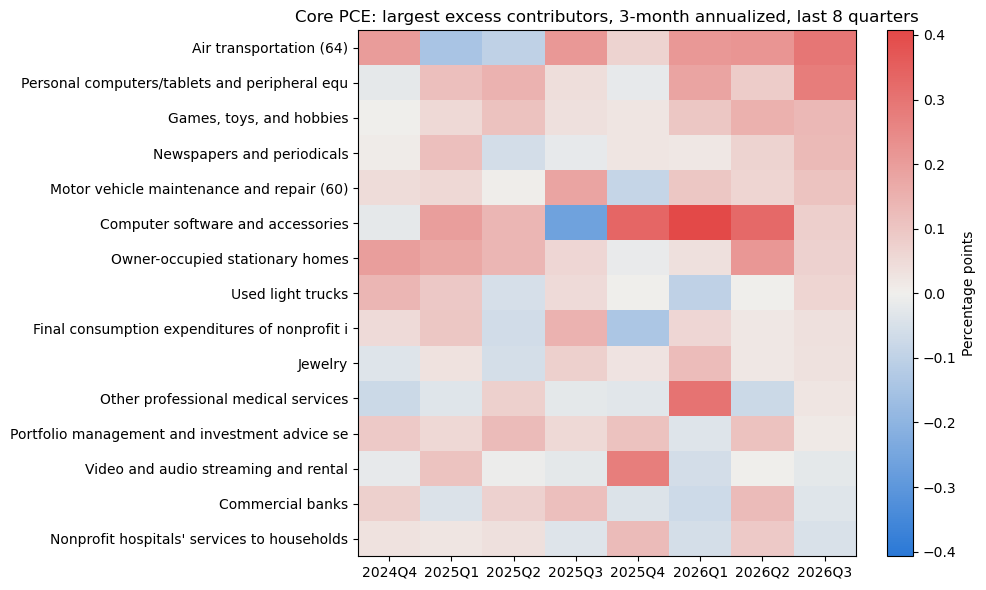

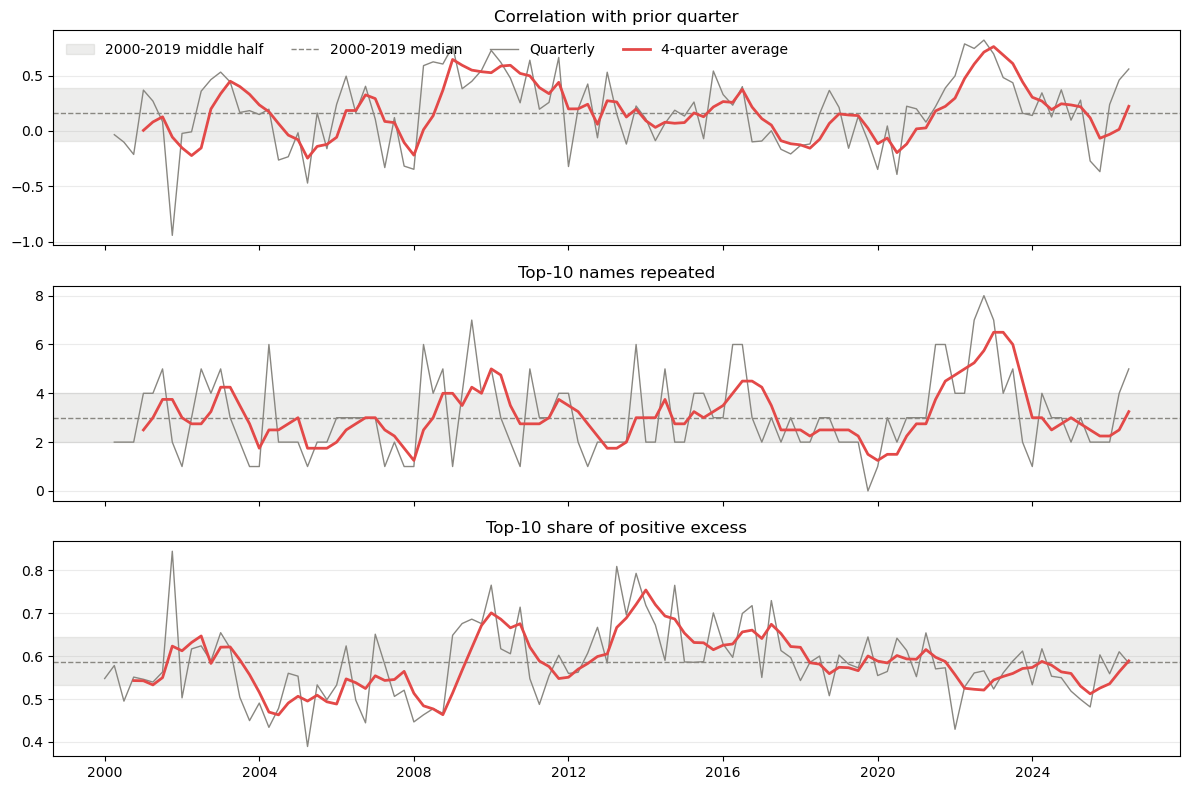

In [17]:
from matplotlib.colors import LinearSegmentedColormap


def plot_persistence(quarterly, measures, name, heatmap_quarters=8):
    # Heatmap: horizontal streaks mean persistence, scattered cells mean rotation
    recent = quarterly.tail(heatmap_quarters)
    leaders = recent.clip(lower=0).sum().nlargest(15).index
    heat = recent[leaders].T.sort_values(recent.index[-1], ascending=False)
    limit = heat.abs().max().max()
    fig, ax = plt.subplots(figsize=(10, 6))
    image = ax.imshow(
        heat, aspect="auto", vmin=-limit, vmax=limit,
        cmap=LinearSegmentedColormap.from_list("excess", [NEGATIVE, "#f0efec", POSITIVE]),
    )
    ax.set_xticks(range(heat.shape[1]), heat.columns.astype(str))
    ax.set_yticks(range(len(heat)), descriptions[heat.index].str[:45])
    fig.colorbar(image, ax=ax, label="Percentage points")
    ax.set_title(f"{name}: largest excess contributors, 3-month annualized, last {heatmap_quarters} quarters")
    plt.tight_layout()
    plt.show()

    # Each measure over time against its benchmark-period range
    baseline = measures.loc[f"{bench_start}Q1":f"{bench_end}Q4"]
    dates = measures.index.to_timestamp()
    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
    for ax, column in zip(axes, measures.columns):
        ax.axhspan(baseline[column].quantile(0.25), baseline[column].quantile(0.75),
                   color=MUTED, alpha=0.15, label=f"{BENCHMARK} middle half")
        ax.axhline(baseline[column].median(), color=MUTED, lw=1, ls="--", label=f"{BENCHMARK} median")
        ax.plot(dates, measures[column], color=MUTED, lw=1, label="Quarterly")
        ax.plot(dates, measures[column].rolling(4).mean(), color=POSITIVE, lw=2, label="4-quarter average")
        ax.set_title(column)
        ax.grid(axis="y", alpha=0.25)
    axes[0].legend(frameon=False, loc="upper left", ncol=4)
    plt.tight_layout()
    plt.show()


plot_persistence(core_quarterly, core_persistence, "Core PCE")

## 4. Checks

The asserts confirm the pieces add up. `checks` compares each anchor with the official average over the benchmark period, shows that excess averages close to zero over that period, and reports the reconstruction residual.

In [18]:
checks = {}
for name, summary, groups in [
    ("Headline", headline_summary, headline_groups),
    ("Core", core_summary, core_groups),
]:
    assert np.allclose(summary["Component excess"] + summary["Mix shift"], summary["Excess over anchor"])
    assert np.allclose(groups.drop(columns="Total").sum(axis=1), groups["Total"])

    residual = summary["Reconstructed inflation"] - summary["Official BEA inflation"]
    in_period = summary.reindex(benchmark_dates)
    checks[name] = {
        "Anchor (%)": summary["Benchmark anchor"].iloc[0],
        f"Official average, {BENCHMARK} (%)": in_period["Official BEA inflation"].mean(),
        f"Average excess over anchor, {BENCHMARK} (pp)": in_period["Excess over anchor"].mean(),
        "Latest reconstruction residual (pp)": residual.iloc[-1],
        "Largest absolute residual (pp)": residual.abs().max(),
    }
checks = pd.DataFrame(checks)
checks.round(3)

NameError: name 'headline_summary' is not defined